# Missing data is rarely random

**MCAR, MAR and MNAR, shown with a simulated health-record example.**

A dataset of patients with diabetes, where 30% of HbA1c results are missing. The *amount* of missing data is the same in every scenario. Only the *reason* changes, and the reason decides whether the analysis is right.

This notebook:

1. Simulates the three missing-data mechanisms on the same patients
2. Compares two common approaches: dropping incomplete rows, and multiple imputation
3. Shows why MAR and MNAR **cannot be told apart from the observed data alone**
4. Runs a simple **sensitivity analysis**, the approach clinical trials use for exactly this problem

> **Data note:** all data is **synthetic**. Ages, HbA1c values, the age-HbA1c relationship, and the 9% cut-off for "poor control" are illustrative assumptions chosen to make the mechanisms visible. They are not clinical estimates.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.optimize import brentq

from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"

## 1. The complete truth

5,000 simulated patients. In this synthetic population, younger patients tend to have higher HbA1c. That relationship is what makes MAR and MNAR matter: if missingness were unrelated to everything, nothing would be biased.

Because we generate the data ourselves, we know the true values, which is never the case in practice.

In [2]:
N = 5_000
POOR_CONTROL = 9.0      # illustrative cut-off for "poorly controlled" (HbA1c %)
MISSING_RATE = 0.30

age = rng.uniform(30, 80, N)
hba1c = 7.8 - 0.03 * (age - 55) + rng.normal(0, 1.1, N)

true_mean = hba1c.mean()
true_poor = (hba1c > POOR_CONTROL).mean()
print(f"True mean HbA1c          : {true_mean:.2f}%")
print(f"True share poorly controlled (>9%): {true_poor:.1%}")

True mean HbA1c          : 7.80%
True share poorly controlled (>9%): 15.4%


## 2. Three reasons a value goes missing

Each scenario removes about 30% of HbA1c values. A helper adjusts the intercept so every mechanism hits the same missing rate, which keeps the comparison fair.

| Mechanism | Story | Missingness depends on |
| --- | --- | --- |
| **MCAR** | A freezer fails and a random batch of samples is lost | Nothing |
| **MAR** | Younger patients attend less often | Age, which **is** recorded |
| **MNAR** | Patients with poorly controlled glucose skip follow-up | HbA1c itself, which is **not** recorded when missing |

In [3]:
def missing_probability(linear_term, target=MISSING_RATE):
    """Shift a logistic model's intercept so the average missing rate equals `target`."""
    intercept = brentq(lambda a: expit(a + linear_term).mean() - target, -20, 20)
    return expit(intercept + linear_term)

prob_missing = {
    "MCAR": np.full(N, MISSING_RATE),
    "MAR":  missing_probability(-0.07 * (age - 55)),    # younger -> more missing
    "MNAR": missing_probability(1.2 * (hba1c - 7.8)),   # higher HbA1c -> more missing
}

missing_mask = {k: rng.random(N) < p for k, p in prob_missing.items()}
observed = {k: np.where(m, np.nan, hba1c) for k, m in missing_mask.items()}

for k, m in missing_mask.items():
    print(f"{k:<5}: {m.mean():.1%} missing")

MCAR : 29.5% missing
MAR  : 29.9% missing
MNAR : 30.2% missing


## 3. Two ways to handle it

- **Drop incomplete rows** (complete-case analysis): the default in many workflows, often without anyone deciding it.
- **Multiple imputation using age:** fill each missing value with a plausible draw predicted from age, repeat 20 times, and average the results. Using several draws, rather than one best guess, keeps the uncertainty about the missing values in the analysis.

In [4]:
N_IMPUTATIONS = 20

def multiple_imputation(obs, n_imp=N_IMPUTATIONS):
    """Return a list of completed HbA1c arrays, imputed from age."""
    X = np.column_stack([age, obs])
    return [
        IterativeImputer(sample_posterior=True, random_state=i).fit_transform(X)[:, 1]
        for i in range(n_imp)
    ]

rows = []
imputations = {}
for k, obs in observed.items():
    kept = obs[~np.isnan(obs)]
    imps = multiple_imputation(obs)
    imputations[k] = imps
    rows.append({
        "Mechanism": k,
        "Mean: drop rows": kept.mean(),
        "Mean: multiple imputation": np.mean([i.mean() for i in imps]),
        "Poor control: drop rows": (kept > POOR_CONTROL).mean(),
        "Poor control: multiple imputation": np.mean([(i > POOR_CONTROL).mean() for i in imps]),
    })

results = pd.DataFrame(rows).set_index("Mechanism")
print(f"Truth: mean {true_mean:.2f}%, poorly controlled {true_poor:.1%}\n")
results.style.format({c: ("{:.2f}" if c.startswith("Mean") else "{:.1%}") for c in results.columns})

Truth: mean 7.80%, poorly controlled 15.4%



,Mean: drop rows,Mean: multiple imputation,Poor control: drop rows,Poor control: multiple imputation
Mechanism,,,,
MCAR,7.80,7.79,15.7%,15.5%
MAR,7.71,7.81,14.0%,16.2%
MNAR,7.44,7.47,6.8%,7.3%


**Reading the table:**

- **MCAR:** both approaches land on the truth. Dropping rows only costs sample size.
- **MAR:** dropping rows under-counts poor control, because younger, higher-HbA1c patients are the ones missing. Imputation using age recovers the truth.
- **MNAR:** **both approaches fail.** The share of poorly controlled patients is badly under-estimated, and imputation doesn't help, because age doesn't explain why the values are missing.

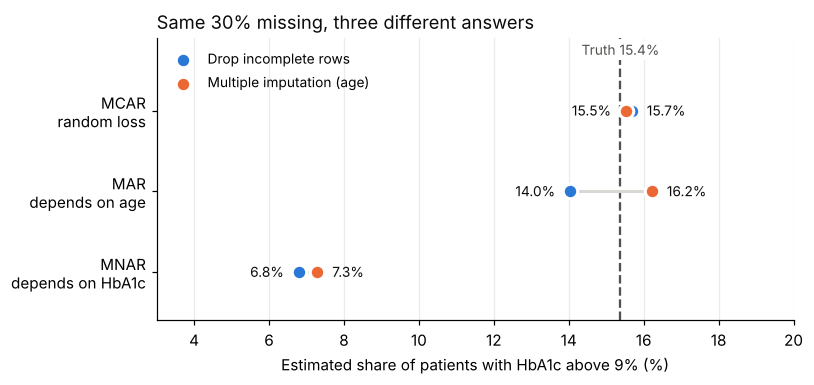

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
mechs = ["MCAR", "MAR", "MNAR"]
y = np.arange(len(mechs))[::-1]
cc = results.loc[mechs, "Poor control: drop rows"].values * 100
mi = results.loc[mechs, "Poor control: multiple imputation"].values * 100

ax.axvline(true_poor * 100, color=MUTED, linestyle="--", linewidth=1.5, zorder=1)
ax.text(true_poor * 100, len(mechs) - 0.35, f"Truth {true_poor:.1%}", color=MUTED,
        ha="center", va="bottom", fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
for yi, a, b in zip(y, cc, mi):
    ax.plot([a, b], [yi, yi], color="#d9d8d4", linewidth=2, zorder=2)
ax.scatter(cc, y, s=90, color=BLUE, zorder=3, edgecolor="white", linewidth=2, label="Drop incomplete rows")
ax.scatter(mi, y, s=90, color=ORANGE, zorder=3, edgecolor="white", linewidth=2, label="Multiple imputation (age)")
for yi, a, b in zip(y, cc, mi):
    left, right = (a, b) if a < b else (b, a)
    ax.text(left - 0.4, yi, f"{left:.1f}%", ha="right", va="center", fontsize=9, color=INK)
    ax.text(right + 0.4, yi, f"{right:.1f}%", ha="left", va="center", fontsize=9, color=INK)

ax.set_yticks(y, ["MCAR\nrandom loss", "MAR\ndepends on age", "MNAR\ndepends on HbA1c"])
ax.set_xlabel("Estimated share of patients with HbA1c above 9% (%)")
ax.set_xlim(3, 20)
ax.set_ylim(-0.6, len(mechs) - 0.1)
ax.grid(axis="x", color="#ecebe7", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.set_title("Same 30% missing, three different answers", loc="left", fontsize=12, color=INK)
plt.tight_layout()
plt.savefig("missing_data_mechanisms.png", bbox_inches="tight", facecolor="white")
plt.show()

## 4. Why the data can't tell you which case you're in

A common check is to ask: *does missingness relate to anything we recorded?* Below, a logistic regression predicts whether HbA1c is missing from age.

- Under **MCAR**, age has essentially no effect. This check *can* rule MCAR out.
- Under **MAR** and **MNAR**, age is a clear predictor in both. Under MNAR that happens only because age is correlated with HbA1c.

From the observed data, MAR and MNAR look the same. The difference lies in the values you never saw, so no test on the observed data can separate them. Only knowledge of *how the data was collected* can.

In [6]:
diag = []
for k, m in missing_mask.items():
    lr = LogisticRegression().fit(((age - 55) / 10).reshape(-1, 1), m)
    young, old = m[age < 45].mean(), m[age >= 65].mean()
    diag.append({"Mechanism": k,
                 "Log-odds of missing per 10 years older": lr.coef_[0, 0],
                 "Missing, under 45": young,
                 "Missing, age 65+": old})
pd.DataFrame(diag).set_index("Mechanism").style.format(
    {"Log-odds of missing per 10 years older": "{:+.2f}",
     "Missing, under 45": "{:.1%}", "Missing, age 65+": "{:.1%}"})

,Log-odds of missing per 10 years older,"Missing, under 45","Missing, age 65+"
Mechanism,,,
MCAR,+0.04,28.7%,31.7%
MAR,-0.67,52.6%,9.7%
MNAR,-0.26,39.7%,20.5%


## 5. Sensitivity analysis: what if the data is MNAR?

Since MNAR can't be ruled out, a trial-style approach is to ask how much the conclusion would change if the missing values were systematically worse than the model assumes.

A simple version is a **delta adjustment**: take the MAR-based imputations and add a shift (delta) to every imputed value, then re-estimate. If the conclusion holds across plausible deltas, it's robust. If it changes, the result depends on an assumption that can't be checked.

ICH E9(R1), the addendum on estimands and sensitivity analysis, describes this principle: analyses that test the main model's assumptions "should then be pre-specified". The deltas below are illustrative.

In [7]:
deltas = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25]
mnar_mask = missing_mask["MNAR"]

sens = []
for d in deltas:
    shares = [((np.where(mnar_mask, imp + d, imp)) > POOR_CONTROL).mean()
              for imp in imputations["MNAR"]]
    sens.append({"Delta added to imputed values (HbA1c %)": d,
                 "Estimated share poorly controlled": np.mean(shares)})
sens_df = pd.DataFrame(sens)
print(f"Truth (unknowable in practice): {true_poor:.1%}")
sens_df.style.format({"Estimated share poorly controlled": "{:.1%}",
                      "Delta added to imputed values (HbA1c %)": "{:.2f}"}).hide(axis="index")

Truth (unknowable in practice): 15.4%


Delta added to imputed values (HbA1c %),Estimated share poorly controlled
0.00,7.3%
0.25,8.6%
0.50,10.4%
0.75,12.5%
1.00,15.0%
1.25,17.8%


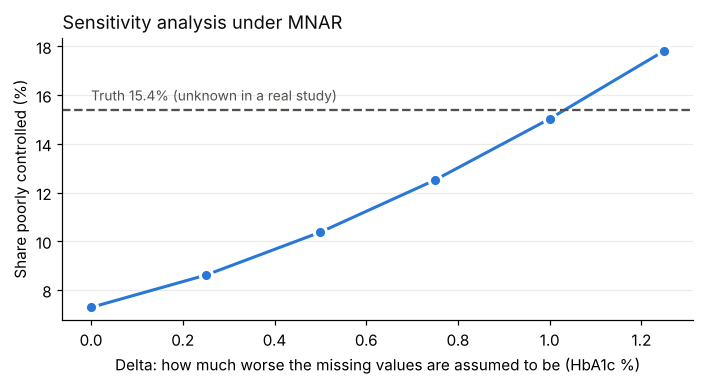

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(sens_df.iloc[:, 0], sens_df.iloc[:, 1] * 100, color=BLUE, linewidth=2,
        marker="o", markersize=8, markeredgecolor="white", markeredgewidth=2)
ax.axhline(true_poor * 100, color=MUTED, linestyle="--", linewidth=1.5)
ax.text(deltas[0], true_poor * 100 + 0.4, f"Truth {true_poor:.1%} (unknown in a real study)",
        color=MUTED, fontsize=9)
ax.set_xlabel("Delta: how much worse the missing values are assumed to be (HbA1c %)")
ax.set_ylabel("Share poorly controlled (%)")
ax.set_title("Sensitivity analysis under MNAR", loc="left", fontsize=12, color=INK)
ax.grid(axis="y", color="#ecebe7", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("sensitivity_analysis.png", bbox_inches="tight", facecolor="white")
plt.show()

In a real study, the true line isn't available. What you report is the range: *"if missing patients were up to X points worse, the estimate would be between A and B."* Whether that range is acceptable is a clinical judgement, not a statistical one.

## Takeaways

- **The same amount of missing data can be harmless or seriously misleading**, depending on why it's missing.
- **Dropping incomplete rows is only safe under MCAR**, which is the least common case in health records.
- **Multiple imputation fixes MAR, not MNAR.** It can only use what was recorded.
- **You cannot test MAR against MNAR with the observed data.** The answer comes from understanding how the data was collected.
- **When MNAR is plausible, report a sensitivity analysis**, and decide its range before seeing the results.

*Synthetic data, illustrative assumptions. Built as a companion to a LinkedIn post on missing data in health records.*